In [1]:
pip install pandas numpy matplotlib seaborn scipy scikit-learn sqlalchemy pyodbc

Note: you may need to restart the kernel to use updated packages.


In [1]:
import pyodbc
pyodbc.drivers()

['SQL Server',
 'Microsoft Access Driver (*.mdb, *.accdb)',
 'Microsoft Excel Driver (*.xls, *.xlsx, *.xlsm, *.xlsb)',
 'Microsoft Access Text Driver (*.txt, *.csv)',
 'ODBC Driver 17 for SQL Server',
 'ODBC Driver 18 for SQL Server',
 'SnowflakeDSIIDriver']

In [2]:
import pandas as pd
from sqlalchemy import create_engine
from urllib.parse import quote_plus

conn_str = (
    "DRIVER={ODBC Driver 17 for SQL Server};"
    "SERVER=DESKTOP-A4QG6CR;"
    "DATABASE=Churn;"
    "Trusted_Connection=yes;"
)
engine = create_engine(f"mssql+pyodbc:///?odbc_connect={quote_plus(conn_str)}")


In [3]:

df = pd.read_sql("SELECT * FROM [dbo.cleaned_spotify_churn]", engine)
df.head()

,user_id,gender,age,country,subscription_type,listening_time,songs_played_per_day,skip_rate,device_type,ads_listened_per_week,offline_listening,is_churned
0,1,Female,54,CA,Free,26,23,0.20,Desktop,31,0,1
1,2,Other,33,DE,Family,141,62,0.34,Web,0,1,0
2,3,Male,38,AU,Premium,199,38,0.04,Mobile,0,1,1
3,4,Female,22,CA,Student,36,2,0.31,Mobile,0,1,0
4,5,Other,29,US,Family,250,57,0.36,Mobile,0,1,1


In [4]:
print(df.shape)
df.info()

(8000, 12)


<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   user_id                8000 non-null   int64  
 1   gender                 8000 non-null   str    
 2   age                    8000 non-null   int64  
 3   country                8000 non-null   str    
 4   subscription_type      8000 non-null   str    
 5   listening_time         8000 non-null   int64  
 6   songs_played_per_day   8000 non-null   int64  
 7   skip_rate              8000 non-null   float64
 8   device_type            8000 non-null   str    
 9   ads_listened_per_week  8000 non-null   int64  
 10  offline_listening      8000 non-null   int64  
 11  is_churned             8000 non-null   int64  
dtypes: float64(1), int64(7), str(4)
memory usage: 750.1 KB


In [9]:
df.isnull().sum()

user_id                  0
gender                   0
age                      0
country                  0
subscription_type        0
listening_time           0
songs_played_per_day     0
skip_rate                0
device_type              0
ads_listened_per_week    0
offline_listening        0
is_churned               0
dtype: int64

In [10]:
df.describe()

,user_id,age,listening_time,songs_played_per_day,skip_rate,ads_listened_per_week,offline_listening,is_churned
count,8000.00000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,4000.50000,37.662125,154.068250,50.127250,0.300127,6.943875,0.747750,0.258875
std,2309.54541,12.740359,84.015596,28.449762,0.173594,13.617953,0.434331,0.438044
min,1.00000,16.000000,10.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,2000.75000,26.000000,81.000000,25.000000,0.150000,0.000000,0.000000,0.000000
50%,4000.50000,38.000000,154.000000,50.000000,0.300000,0.000000,1.000000,0.000000
75%,6000.25000,49.000000,227.000000,75.000000,0.450000,5.000000,1.000000,1.000000
max,8000.00000,59.000000,299.000000,99.000000,0.600000,49.000000,1.000000,1.000000


In [11]:
# Churn by category
for col in ["gender", "country", "subscription_type", "device_type"]:
    print(df.groupby(col)["is_churned"].mean().round(3).sort_values(ascending=False), "\n")

gender
Female    0.263
Other     0.262
Male      0.252
Name: is_churned, dtype: float64 

country
PK    0.275
DE    0.273
FR    0.272
AU    0.257
US    0.254
CA    0.248
UK    0.247
IN    0.243
Name: is_churned, dtype: float64 

subscription_type
Family     0.275
Student    0.262
Premium    0.251
Free       0.249
Name: is_churned, dtype: float64 

device_type
Mobile     0.269
Desktop    0.257
Web        0.250
Name: is_churned, dtype: float64 



In [12]:
# Numeric columns vs churn
num_cols = ["age", "listening_time", "songs_played_per_day", "skip_rate",
            "ads_listened_per_week", "offline_listening"]
df.groupby("is_churned")[num_cols].mean().round(2)

,age,listening_time,songs_played_per_day,skip_rate,ads_listened_per_week,offline_listening
is_churned,,,,,,
0,37.63,154.45,49.97,0.3,6.96,0.74
1,37.75,152.98,50.58,0.3,6.89,0.76


## Behavior and Engagement

In [13]:
# Quick check: what values does offline_listening take?
df["offline_listening"].describe()

count    8000.000000
mean        0.747750
std         0.434331
min         0.000000
25%         0.000000
50%         1.000000
75%         1.000000
max         1.000000
Name: offline_listening, dtype: float64


**Offline listening is a yes/no flag, and about 75% of users use it.** The average of 0.748 means roughly 5,980 of 8,000 users listen offline and about 2,020 do not. The only values are 0 and 1, and the spread (0.43) matches a yes/no variable, so it should be treated as a category, not as an amount.


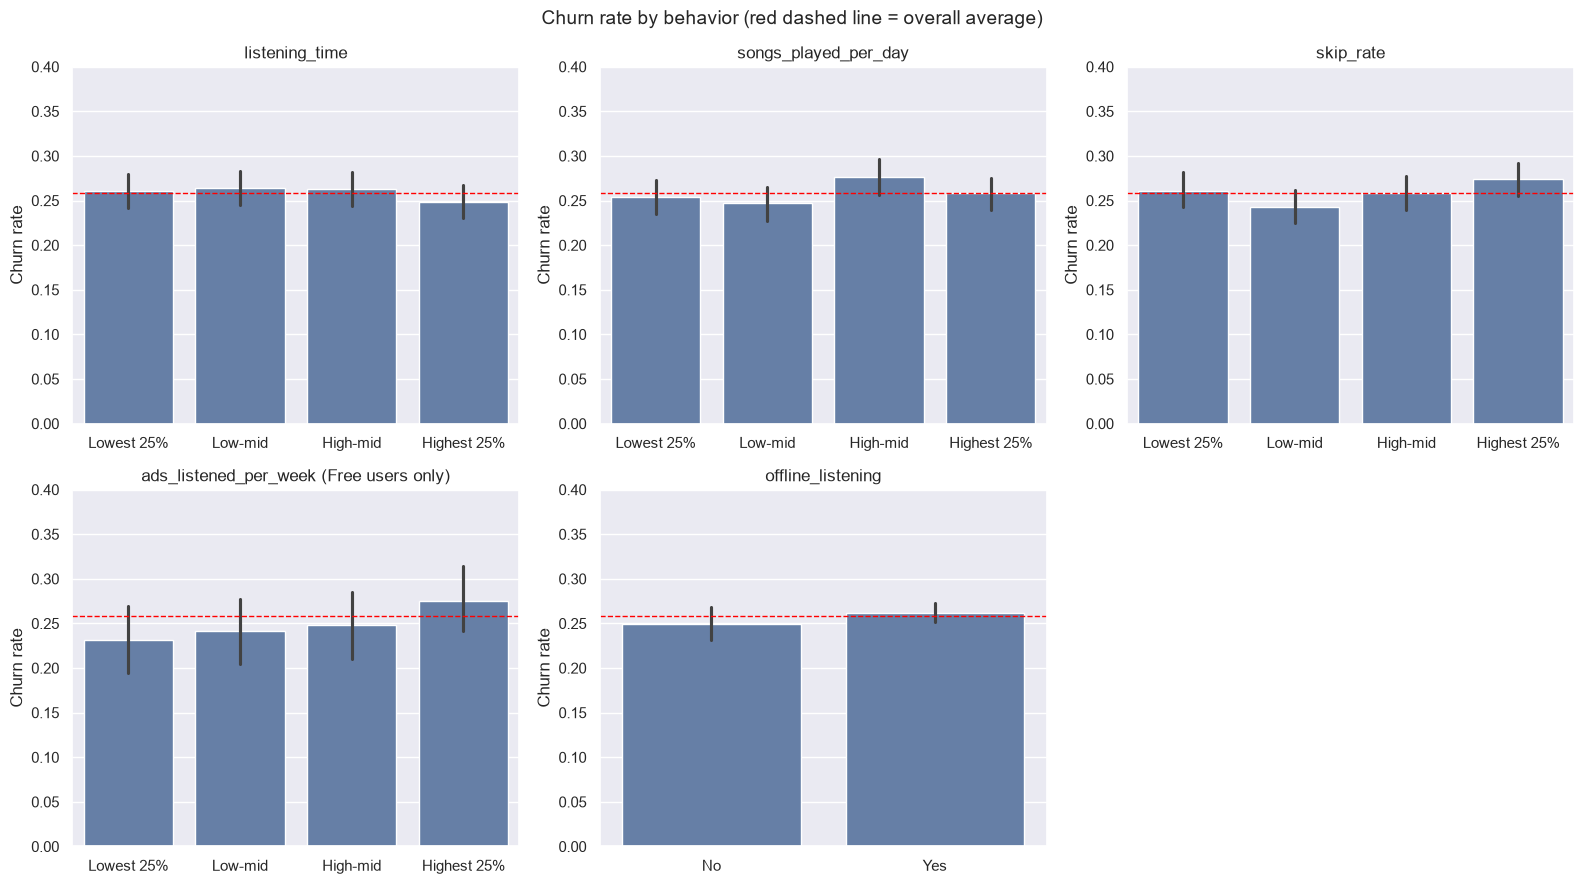

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
overall = df["is_churned"].mean()
labels = ["Lowest 25%", "Low-mid", "High-mid", "Highest 25%"]

# Top row: usage behaviors split into four equal-sized groups
for ax, col in zip(axes[0], ["listening_time", "songs_played_per_day", "skip_rate"]):
    band = pd.qcut(df[col].rank(method="first"), 4, labels=labels)
    sns.barplot(x=band, y=df["is_churned"], errorbar=("ci", 95), color="#5b7db1", ax=ax)
    ax.axhline(overall, color="red", linestyle="--", linewidth=1)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Churn rate")
    ax.set_ylim(0, 0.4)

# Ads: Free users only, because only they hear ads
free = df[df["subscription_type"] == "Free"]
ads_band = pd.qcut(free["ads_listened_per_week"].rank(method="first"), 4, labels=labels)
sns.barplot(x=ads_band, y=free["is_churned"], errorbar=("ci", 95), color="#5b7db1", ax=axes[1][0])
axes[1][0].axhline(overall, color="red", linestyle="--", linewidth=1)
axes[1][0].set_title("ads_listened_per_week (Free users only)")
axes[1][0].set_xlabel("")
axes[1][0].set_ylabel("Churn rate")
axes[1][0].set_ylim(0, 0.4)

# Offline listening: yes/no
sns.barplot(x=df["offline_listening"].map({0: "No", 1: "Yes"}), y=df["is_churned"],
            errorbar=("ci", 95), color="#5b7db1", ax=axes[1][1])
axes[1][1].axhline(overall, color="red", linestyle="--", linewidth=1)
axes[1][1].set_title("offline_listening")
axes[1][1].set_xlabel("")
axes[1][1].set_ylabel("Churn rate")
axes[1][1].set_ylim(0, 0.4)

axes[1][2].axis("off")
plt.suptitle("Churn rate by behavior (red dashed line = overall average)", fontsize=14)
plt.tight_layout()
plt.show()

## Does user behavior predict churn?

Churn stays within about 3 points of the 26% average across every level of
listening time, songs per day, skip rate and offline listening. Among Free
users, heavier ad exposure shows a slight upward drift, but the groups
overlap too much to confirm it.

**Takeaway:** usage behavior is not an early-warning signal for churn here.

In [16]:
# Churn rate across bands of each behavior (quartiles)
for col in ["listening_time", "skip_rate", "ads_listened_per_week", "songs_played_per_day"]:
    bands = pd.qcut(df[col], 4, duplicates="drop")
    print(df.groupby(bands, observed=True)["is_churned"].mean().round(3), "\n")

listening_time
(9.999, 81.0]     0.261
(81.0, 154.0]     0.264
(154.0, 227.0]    0.264
(227.0, 299.0]    0.247
Name: is_churned, dtype: float64 

skip_rate
(-0.001, 0.15]    0.259
(0.15, 0.3]       0.245
(0.3, 0.45]       0.254
(0.45, 0.6]       0.278
Name: is_churned, dtype: float64 

ads_listened_per_week
(-0.001, 5.0]    0.262
(5.0, 49.0]      0.250
Name: is_churned, dtype: float64 

songs_played_per_day
(0.999, 25.0]    0.254
(25.0, 50.0]     0.245
(50.0, 75.0]     0.277
(75.0, 99.0]     0.259
Name: is_churned, dtype: float64 



In [17]:
# Age groups
df["age_group"] = pd.cut(df["age"], bins=[0, 24, 34, 44, 120],
                         labels=["Under 25", "25-34", "35-44", "45+"])
print(df.groupby("age_group", observed=True)["is_churned"].mean().round(3))

age_group
Under 25    0.250
25-34       0.269
35-44       0.253
45+         0.262
Name: is_churned, dtype: float64


## which segments are the riskiest?

In [20]:
print(df["ads_listened_per_week"].describe())
print(df["ads_listened_per_week"].value_counts().head())

count    8000.000000
mean        6.943875
std        13.617953
min         0.000000
25%         0.000000
50%         0.000000
75%         5.000000
max        49.000000
Name: ads_listened_per_week, dtype: float64
ads_listened_per_week
0     5982
47      58
44      57
16      55
39      53
Name: count, dtype: int64


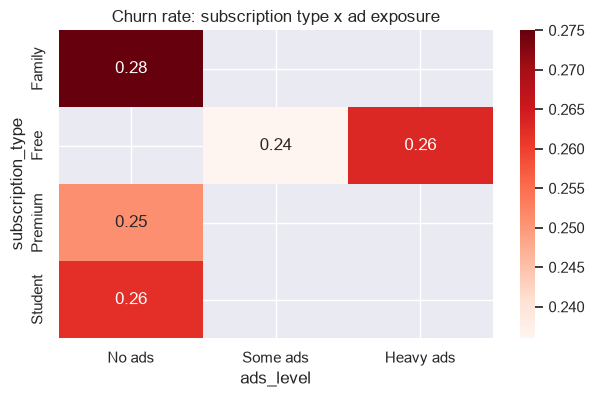

In [21]:
ads = df["ads_listened_per_week"]
cut_point = ads[ads > 0].median()

df["ads_level"] = np.where(ads == 0, "No ads",
                  np.where(ads <= cut_point, "Some ads", "Heavy ads"))
df["ads_level"] = pd.Categorical(df["ads_level"],
                                 categories=["No ads", "Some ads", "Heavy ads"],
                                 ordered=True)

pivot1 = df.pivot_table(index="subscription_type", columns="ads_level",
                        values="is_churned", aggfunc="mean", observed=True).round(3)

plt.figure(figsize=(7, 4))
sns.heatmap(pivot1, annot=True, cmap="Reds", fmt=".2f")
plt.title("Churn rate: subscription type x ad exposure")
plt.show()

## Do ads push users to churn?
Ads cannot be compared across plans because only Free users hear them. Paid plans show zero ad exposure, making the blank heatmap cells expected structural gaps.

Within Free subscribers, heavy-ad listeners churn at 26% compared to 24% for those with lower ad exposure. While this aligns with our regression model, the 2-point gap sits within the margin of error and remains a pattern to monitor rather than a proven driver. Furthermore, Family plans exhibit the highest overall churn (28%) despite having zero ad exposure.

Takeaway: Ad load is a weak, unconfirmed churn factor. Test ad-reduction offers exclusively on high-ad Free users before deploying broader retention interventions.

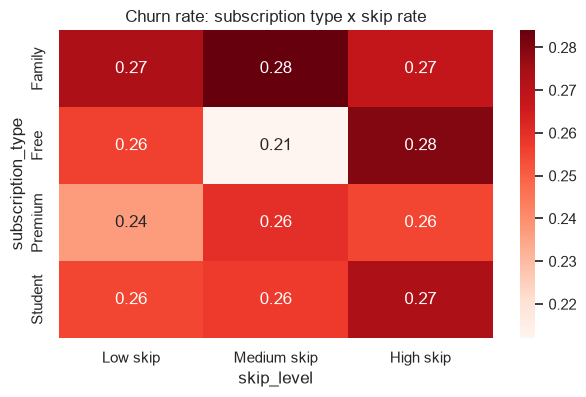

In [22]:
# Subscription type x skip rate
df["skip_level"] = pd.qcut(df["skip_rate"], 3,
                           labels=["Low skip", "Medium skip", "High skip"], duplicates="drop")
pivot2 = df.pivot_table(index="subscription_type", columns="skip_level",
                        values="is_churned", aggfunc="mean", observed=True).round(3)

plt.figure(figsize=(7, 4))
sns.heatmap(pivot2, annot=True, cmap="Reds", fmt=".2f")
plt.title("Churn rate: subscription type x skip rate")
plt.show()

## Does skip rate affect churn?

**Rarely.** Overall churn remains stable between 24% and 28% regardless of skip volume. Across most tiers—including Family plans—skip behavior shows virtually no impact on retention.

The only exception appears in the **Free tier**, where high skippers reach **28% churn** compared to **21%** for medium skippers. However, because low skippers sit at 26%, this non-linear gap may reflect sample variance rather than a clear trend.

**Therefore**, skip rate is a weak standalone churn indicator and should not be used as an automated retention trigger. High-skip Free users are the only sub-segment warranting minor follow-up.

In [23]:
# Riskiest country + subscription combinations (ignoring tiny groups)
combo = (df.groupby(["country", "subscription_type"])["is_churned"]
           .agg(churn_rate="mean", users="count").round(3).reset_index())
combo[combo["users"] >= 30].sort_values("churn_rate", ascending=False).head(10)

,country,subscription_type,churn_rate,users
23,PK,Student,0.316,247
0,AU,Family,0.304,263
20,PK,Family,0.298,252
24,UK,Family,0.290,207
11,DE,Student,0.288,257
9,DE,Free,0.281,249
28,US,Family,0.280,243
15,FR,Student,0.280,232
14,FR,Premium,0.277,274
27,UK,Student,0.276,228


## Do subscription type and device affect churn?

                   churn_rate  users
subscription_type                   
Family                  0.275   1908
Student                 0.262   1959
Premium                 0.251   2115
Free                    0.249   2018


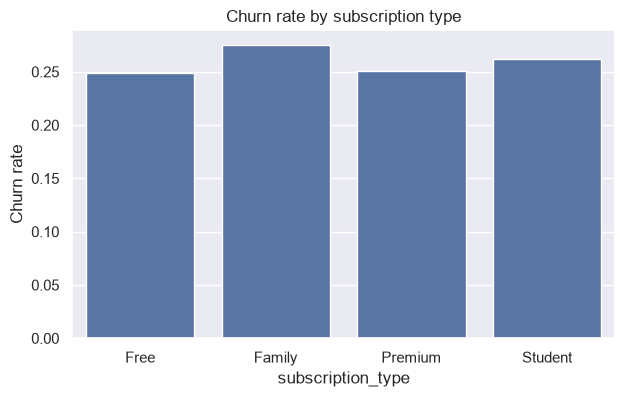

In [24]:
# Churn rate and user counts by subscription type
sub = df.groupby("subscription_type")["is_churned"].agg(["mean", "count"]).round(3)
sub.columns = ["churn_rate", "users"]
print(sub.sort_values("churn_rate", ascending=False))

plt.figure(figsize=(7, 4))
sns.barplot(data=df, x="subscription_type", y="is_churned", errorbar=None)
plt.ylabel("Churn rate")
plt.title("Churn rate by subscription type")
plt.show()

## Does subscription type affect churn?

**Barely**. Family plans have the highest churn (27.5%), followed by Student (26.2%), Premium (25.1%), and Free (24.9%). Unexpectedly, paying subscribers are just as likely to churn as free users.

The 2.6% gap between Family and Free plans is statistically minor, meaning plan type alone is a weak indicator for predicting churn. Lost users are split almost evenly across all four tiers (~25% each).

**Takeaway**: Focus retention efforts beyond subscription tier alone, Family plans warrant extra monitoring, but should be analyzed alongside ad load and country-specific data.

             churn_rate  users
device_type                   
Mobile            0.269   2599
Desktop           0.257   2778
Web               0.250   2623


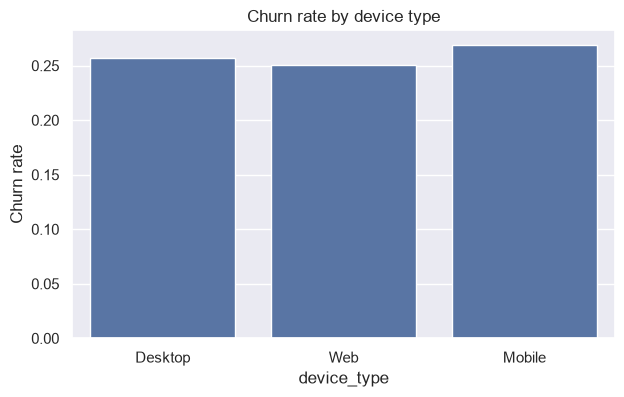

In [25]:
# Churn rate by device type
dev = df.groupby("device_type")["is_churned"].agg(["mean", "count"]).round(3)
dev.columns = ["churn_rate", "users"]
print(dev.sort_values("churn_rate", ascending=False))

plt.figure(figsize=(7, 4))
sns.barplot(data=df, x="device_type", y="is_churned", errorbar=None)
plt.ylabel("Churn rate")
plt.title("Churn rate by device type")
plt.show()

## Does device type affect churn?

**Device is not where Spotify's churn problem sits.** Churn is 26.9% on Mobile, 25.7% on Desktop and 25.0% on Web, within about 2 points of the 26% average. Mobile is highest, but even the gap between Mobile and Web is under 2 points, and the logistic regression shows the same weak pattern (Mobile about +6% in odds, Web about -4%).

**Volume is split almost evenly:** Desktop (715), Mobile (699) and Web (657) each account for roughly a third of all churned users, so no single platform dominates the loss.

**Takeaway:** device-specific retention campaigns (for example, a Mobile-only offer) would reach about a third of churners at best, with little gain in targeting. Retention effort is better spent on the factors that separate users more strongly, such as plan type and ad exposure.

*Limitations: differences between devices are small, and this view does not account for plan or country.*

In [3]:
from scipy import stats

table = pd.crosstab(df["device_type"], df["is_churned"])
chi2, p, dof, expected = stats.chi2_contingency(table)
print(f"Chi-square p-value: {p:.3f}")

Chi-square p-value: 0.305


In [7]:
rows = []
for col in ["gender", "country", "subscription_type", "device_type", "age_group"]:
    t = pd.crosstab(df[col], df["is_churned"])
    chi2, p, _, _ = stats.chi2_contingency(t)
    rows.append({"feature": col, "p_value": round(p, 4), "significant": p < 0.05})

for col in ["age", "listening_time", "songs_played_per_day", "skip_rate",
            "ads_listened_per_week", "offline_listening"]:
    stat, p = stats.mannwhitneyu(df.loc[df["is_churned"] == 1, col],
                                 df.loc[df["is_churned"] == 0, col])
    rows.append({"feature": col, "p_value": round(p, 4), "significant": p < 0.05})

pd.DataFrame(rows).sort_values("p_value")

,feature,p_value,significant
8,skip_rate,0.1499,False
2,subscription_type,0.2161,False
10,offline_listening,0.2540,False
3,device_type,0.3055,False
9,ads_listened_per_week,0.3967,False
7,songs_played_per_day,0.3985,False
6,listening_time,0.4982,False
1,country,0.5449,False
4,age_group,0.5693,False
0,gender,0.6005,False


## Are these differences statistically significant?

In [26]:
from scipy import stats

# Numeric features: churned vs retained (Mann-Whitney U, no normality assumption)
rows = []
for col in ["age", "listening_time", "songs_played_per_day", "skip_rate",
            "ads_listened_per_week", "offline_listening"]:
    churned = df.loc[df["is_churned"] == 1, col]
    retained = df.loc[df["is_churned"] == 0, col]
    stat, p = stats.mannwhitneyu(churned, retained)
    rows.append({"feature": col,
                 "churned_median": churned.median(),
                 "retained_median": retained.median(),
                 "p_value": p,
                 "significant": p < 0.05})
pd.DataFrame(rows).round(4)

,feature,churned_median,retained_median,p_value,significant
0,age,38.00,38.0,0.7352,False
1,listening_time,153.00,155.0,0.4982,False
2,songs_played_per_day,52.00,50.0,0.3985,False
3,skip_rate,0.31,0.3,0.1499,False
4,ads_listened_per_week,0.00,0.0,0.3967,False
5,offline_listening,1.00,1.0,0.2540,False


In [27]:
# Categorical features: is churn independent of the category? (chi-square)
rows = []
for col in ["gender", "country", "subscription_type", "device_type"]:
    table = pd.crosstab(df[col], df["is_churned"])
    chi2, p, dof, expected = stats.chi2_contingency(table)
    rows.append({"feature": col, "chi2": chi2, "p_value": p, "significant": p < 0.05})
pd.DataFrame(rows).round(4)

,feature,chi2,p_value,significant
0,gender,1.0201,0.6005,False
1,country,5.9563,0.5449,False
2,subscription_type,4.4575,0.2161,False
3,device_type,2.3716,0.3055,False


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

cat_cols = ["gender", "country", "subscription_type", "device_type"]
num_cols = ["age", "listening_time", "songs_played_per_day", "skip_rate",
            "ads_listened_per_week", "offline_listening"]

X = df[cat_cols + num_cols]
y = df["is_churned"]

pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),                 # puts numeric features on one scale
    ("cat", OneHotEncoder(drop="first"), cat_cols)       # drops one category per column as the baseline
])

logit = Pipeline([
    ("pre", pre),
    ("lr", LogisticRegression(max_iter=1000, class_weight="balanced"))
])
logit.fit(X, y)

# Coefficients and odds ratios
names = logit.named_steps["pre"].get_feature_names_out()
coefs = logit.named_steps["lr"].coef_[0]

effects = pd.DataFrame({"feature": names, "coefficient": coefs})
effects["feature"] = effects["feature"].str.replace("num__", "").str.replace("cat__", "")
effects["odds_ratio"] = np.exp(effects["coefficient"])
effects["direction"] = np.where(effects["coefficient"] > 0, "Raises churn risk", "Lowers churn risk")
effects = effects.reindex(effects["coefficient"].abs().sort_values(ascending=False).index)

effects.round(3)

,feature,coefficient,odds_ratio,direction
5,offline_listening,0.123,1.130,Raises churn risk
16,subscription_type_Premium,-0.120,0.887,Lowers churn risk
4,ads_listened_per_week,0.092,1.097,Raises churn risk
12,country_PK,0.086,1.090,Raises churn risk
9,country_DE,0.081,1.084,Raises churn risk
10,country_FR,0.080,1.084,Raises churn risk
17,subscription_type_Student,-0.070,0.932,Lowers churn risk
11,country_IN,-0.067,0.935,Lowers churn risk
18,device_type_Mobile,0.057,1.059,Raises churn risk
6,gender_Male,-0.052,0.949,Lowers churn risk


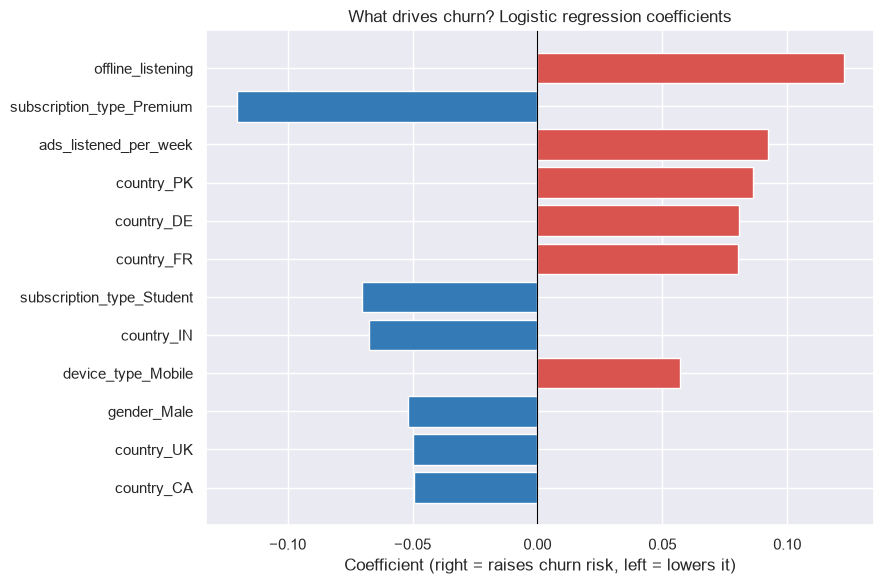

In [11]:
# Chart: red bars raise churn risk, blue bars lower it
top = effects.head(12).iloc[::-1]
colors = np.where(top["coefficient"] > 0, "#d9534f", "#337ab7")

plt.figure(figsize=(9, 6))
plt.barh(top["feature"], top["coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient (right = raises churn risk, left = lowers it)")
plt.title("What drives churn? Logistic regression coefficients")
plt.tight_layout()
plt.show()

## What drives churn?

No single factor strongly drives churn. The largest effect is only about a 13% change in odds, so risk comes from many small influences.

Raises risk: offline listening (+13%), ads heard per week (+10%), mobile devices (+6%), and some countries (Pakistan, Germany, France).

Lowers risk: Premium (-11%) and Student plans (-7%), plus India, UK and Canada.

Takeaway: moving heavy-ad users to Premium or Student plans is the clearest retention lever. Offline listening needs a closer look, because it runs against expectations.

Limitation: these are associations, not causes, and the effects are small.


In [6]:
df["age_group"] = pd.cut(df["age"], bins=[0, 24, 34, 44, 120],
                         labels=["Under 25", "25-34", "35-44", "45+"])

segments = {
    "Subscription type": ["subscription_type"],
    "Country": ["country"],
    "Device": ["device_type"],
    "Age group": ["age_group"],
    "Gender": ["gender"],
    "Country x Subscription": ["country", "subscription_type"],
}

total_churned = df["is_churned"].sum()
parts = []

for name, cols in segments.items():
    g = (df.groupby(cols, observed=True)["is_churned"]
           .agg(users="count", churned_users="sum")
           .reset_index())
    g["segment_type"] = name
    g["segment"] = g[cols].astype(str).agg(" | ".join, axis=1)
    g["churn_rate"] = (g["churned_users"] / g["users"]).round(3)
    g["share_of_all_churn"] = (g["churned_users"] / total_churned).round(3)
    parts.append(g[["segment_type", "segment", "users", "churned_users",
                    "churn_rate", "share_of_all_churn"]])

money = pd.concat(parts, ignore_index=True)
money = money[money["users"] >= 30]
money.to_csv("output/churn_where_is_the_money.csv", index=False)

money.sort_values("churned_users", ascending=False).head(10)

,segment_type,segment,users,churned_users,churn_rate,share_of_all_churn
18,Age group,45+,2790,731,0.262,0.353
12,Device,Desktop,2778,715,0.257,0.345
13,Device,Mobile,2599,699,0.269,0.338
19,Gender,Female,2659,699,0.263,0.338
21,Gender,Other,2650,694,0.262,0.335
20,Gender,Male,2691,678,0.252,0.327
14,Device,Web,2623,657,0.250,0.317
2,Subscription type,Premium,2115,530,0.251,0.256
0,Subscription type,Family,1908,525,0.275,0.254
3,Subscription type,Student,1959,513,0.262,0.248


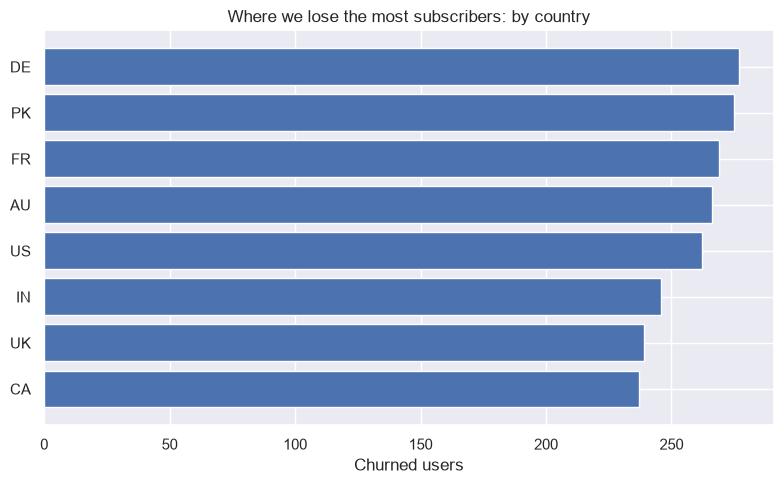

In [15]:
# Chart: lost subscribers by country
top = (money[money["segment_type"] == "Country"]
       .sort_values("churned_users"))

plt.figure(figsize=(8, 5))
plt.barh(top["segment"], top["churned_users"])
plt.xlabel("Churned users")
plt.title("Where we lose the most subscribers: by country")
plt.tight_layout()
plt.show()

## Where is the money? Where we lose subscribers

Churn is spread evenly, so there is no single hotspot.About 2,070 of 8,000 users (26%) churned, and every segment sits within about 1.5 points of that average.

- **Country**: Germany, Pakistan and France lose the most subscribers (about 270-280 each). Canada and the UK lose the fewest (about 240).
- **Age:** users aged 45+ account for the largest share of churn (35%).
- **Device:** Desktop (34.5%) and Mobile (33.8%) account for the most churn.
- **Plan:** Family has the highest churn rate (27.5%) and Premium the lowest (25.1%).

**Takeaway:** the biggest losses come from the biggest groups, not from unusually risky ones. Retention efforts should start in Germany, Pakistan and France, and with Family plan users.

*Limitations*: there is no revenue column, so lost subscribers stand in for lost money, and the differences between segments are small.

## Can we predict who will churn?


In [8]:
import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import roc_auc_score

df["age_group"] = pd.cut(df["age"], bins=[0, 24, 34, 44, 120],
                         labels=["Under 25", "25-34", "35-44", "45+"])
cat_cols = ["gender", "country", "subscription_type", "device_type"]
num_cols = ["age", "listening_time", "songs_played_per_day", "skip_rate",
            "ads_listened_per_week", "offline_listening"]
X, y = df[cat_cols + num_cols], df["is_churned"]

model = Pipeline([
    ("pre", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)],
                              remainder="passthrough")),
    ("rf", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                  random_state=42, n_jobs=-1))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
df["churn_probability"] = cross_val_predict(model, X, y, cv=cv, method="predict_proba")[:, 1]
print("ROC-AUC:", round(roc_auc_score(y, df["churn_probability"]), 3))

high, med = df["churn_probability"].quantile([0.80, 0.50])
df["risk_level"] = np.where(df["churn_probability"] >= high, "High",
                   np.where(df["churn_probability"] >= med, "Medium", "Low"))

risk = df[["user_id", "country", "subscription_type", "device_type", "age_group",
           "is_churned", "churn_probability", "risk_level"]].round(3)
risk.sort_values("churn_probability", ascending=False).to_csv("output/churn_risk_list.csv", index=False)

print(df.groupby("risk_level")["is_churned"].agg(["mean", "count"]).round(3))

ROC-AUC: 0.514
             mean  count
risk_level              
High        0.283   1652
Low         0.251   3950
Medium      0.254   2398



*Method: a random forest scored every user with 5-fold cross-validation, and users were grouped into High (top 20%), Medium and Low risk.*

**The model has almost no predictive power.** The ROC-AUC is 0.514, barely above the 0.5 of random guessing. Actual churn is 28.3% in the High group versus 25.4% in Medium and 25.1% in Low, only about 3 points apart.

**Conclusion:** the available columns say very little about who will churn, so this model should not be used to target retention offers. Richer data (tenure, revenue, support contacts, usage trends) is needed before retesting.